<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Mini Project1</h3>
</div>

<img src = "https://www.cyclonis.com/images/2020/03/googleplay.jpg" width=50%>

## Importing the libraries

In [ ]:
# Install required core packages
%pip install numpy pandas matplotlib seaborn

In [2]:
# Import necessary libraries for data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [3]:
# Ignore warning messages and configure visual aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette(sns.color_palette("Set2"))

## Load and Prepare Data

In [4]:
# Load the dataset from the CSV file into a pandas DataFrame
df = pd.read_csv('googleplaystore.csv')

In [5]:
# Inspect the first 5 rows of the dataset
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## EDA

In [6]:
# Check dataset structure, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


In [7]:
# Count missing values in each column
print(df.isnull().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


In [8]:
# Generate descriptive statistics for numerical columns
display(df.describe())

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


## Data Preprocessing

In [9]:
# Keep only valid ratings between 0 and 5.0 (remove data entry errors)
df = df[df['Rating'] <= 5.0]

In [10]:
# Strip '+' and ',' from Installs and convert to integer/numeric
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')

In [11]:
# Strip currency symbol '$' and convert Price to float
df['Price'] = df['Price'].str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

In [12]:
# Convert Reviews count to numeric format
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

In [13]:
# Convert 'Size' strings (e.g., '19M', '500k') into numeric Megabytes (MB)
def convert_size_to_mb(val):
    if isinstance(val, str):
        if 'M' in val:
            return float(val.replace('M', ''))
        elif 'k' in val:
            return float(val.replace('k', '')) / 1024
    return np.nan

df['Size_MB'] = df['Size'].apply(convert_size_to_mb)

In [14]:
# Drop rows with null values across key numeric metrics
df = df.dropna(subset=['Rating', 'Installs', 'Price', 'Reviews'])

## Strorytelling - Visualization

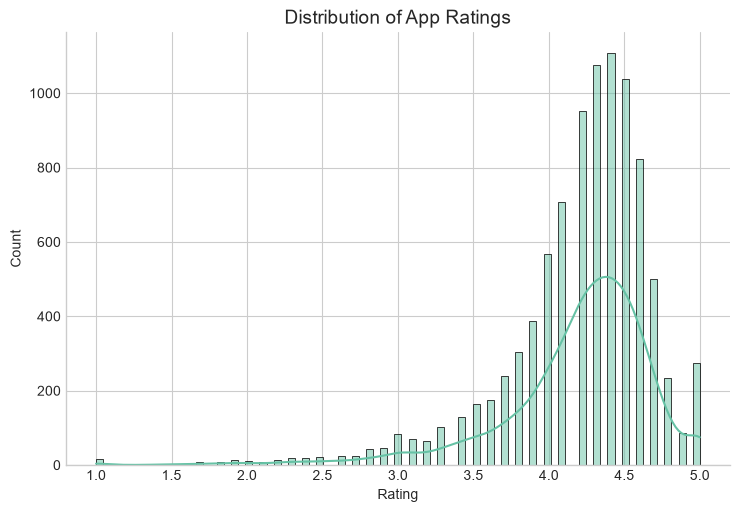

In [15]:
# Visualize the distribution of app ratings with a KDE curve
sns.displot(data=df, x='Rating', kde=True, fill=True, height=5, aspect=1.5)
plt.title('Distribution of App Ratings', fontsize=14)
plt.show()

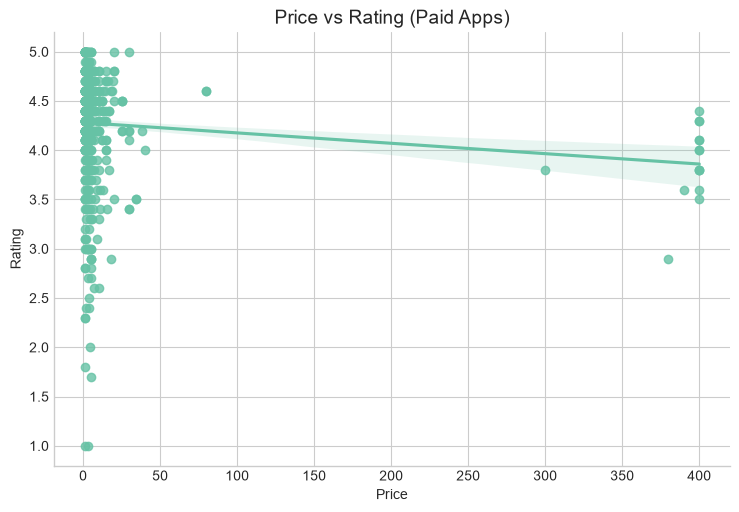

In [16]:
# Linear relationship between Price and Rating specifically for Paid applications
paid_apps = df[df['Type'] == 'Paid']
sns.lmplot(data=paid_apps, x='Price', y='Rating', height=5, aspect=1.5)
plt.title('Price vs Rating (Paid Apps)', fontsize=14)
plt.show()

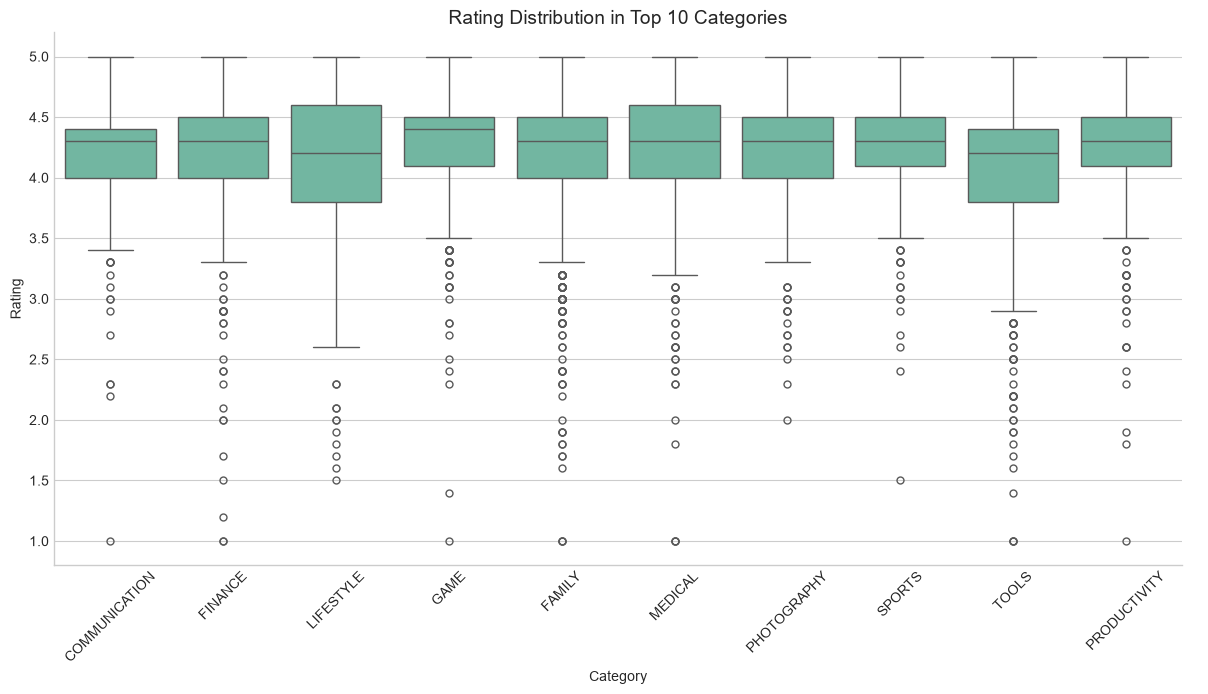

In [17]:
# Boxplot of ratings among the top 10 most frequent app categories
top_categories = df['Category'].value_counts().head(10).index
df_top = df[df['Category'].isin(top_categories)]

sns.catplot(data=df_top, x='Category', y='Rating', kind='box', height=6, aspect=2)
plt.xticks(rotation=45)
plt.title('Rating Distribution in Top 10 Categories', fontsize=14)
plt.show()

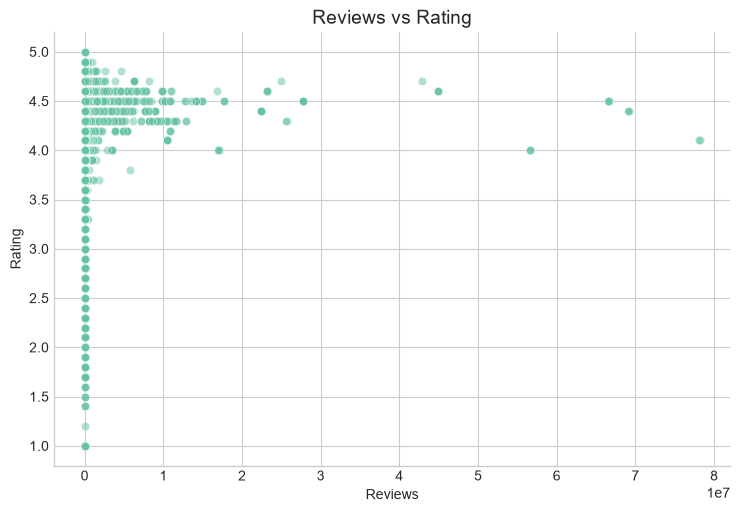

In [18]:
# Scatter plot examining user engagement (Reviews) against Rating
sns.relplot(data=df, x='Reviews', y='Rating', kind='scatter', alpha=0.5, height=5, aspect=1.5)
plt.title('Reviews vs Rating', fontsize=14)
plt.show()

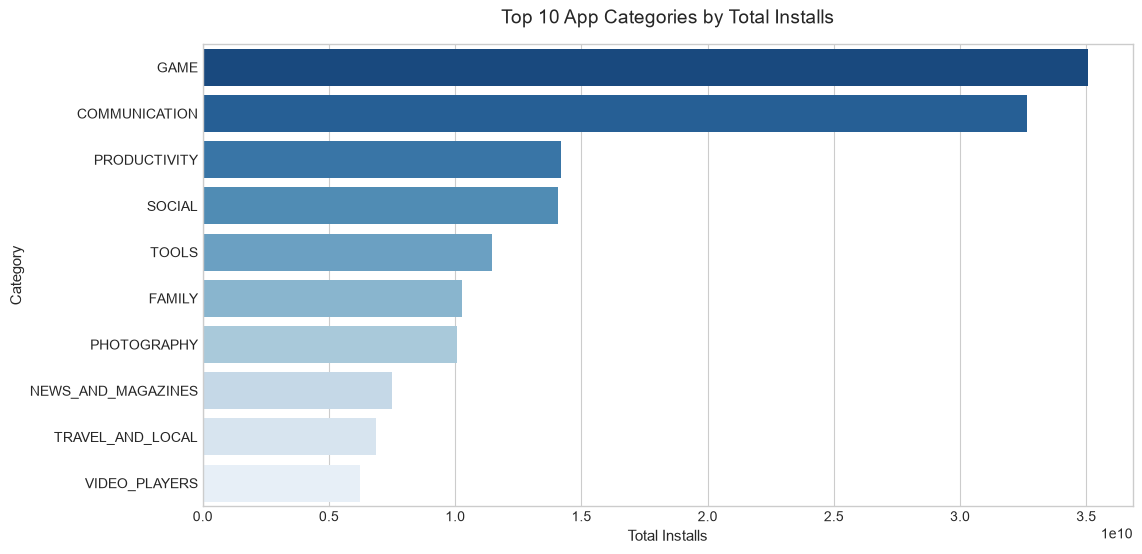

In [19]:
# Identify categories driving the highest market demand in terms of installations
top_installs_cat = df.groupby('Category')['Installs'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=top_installs_cat, x='Installs', y='Category', palette='Blues_r')
plt.title('Top 10 App Categories by Total Installs', fontsize=14, pad=15)
plt.xlabel('Total Installs', fontsize=11)
plt.ylabel('Category', fontsize=11)
plt.show()

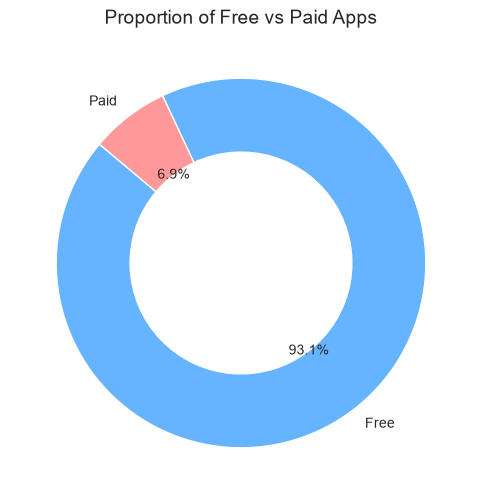

In [20]:
# Proportional market share between Free and Paid apps
type_counts = df['Type'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=140, 
        colors=['#66b3ff', '#ff9999'], wedgeprops=dict(width=0.4, edgecolor='white'))
plt.title('Proportion of Free vs Paid Apps', fontsize=14)
plt.show()

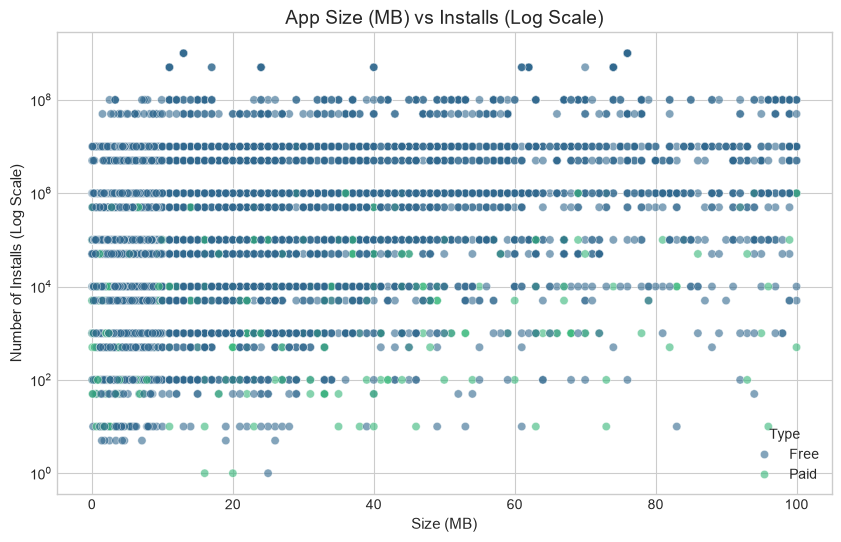

In [21]:
# Correlation between file size (MB) and install volume on a logarithmic scale
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.dropna(subset=['Size_MB']), x='Size_MB', y='Installs', hue='Type', alpha=0.6, palette='viridis')
plt.yscale('log')
plt.title('App Size (MB) vs Installs (Log Scale)', fontsize=14)
plt.xlabel('Size (MB)', fontsize=11)
plt.ylabel('Number of Installs (Log Scale)', fontsize=11)
plt.show()

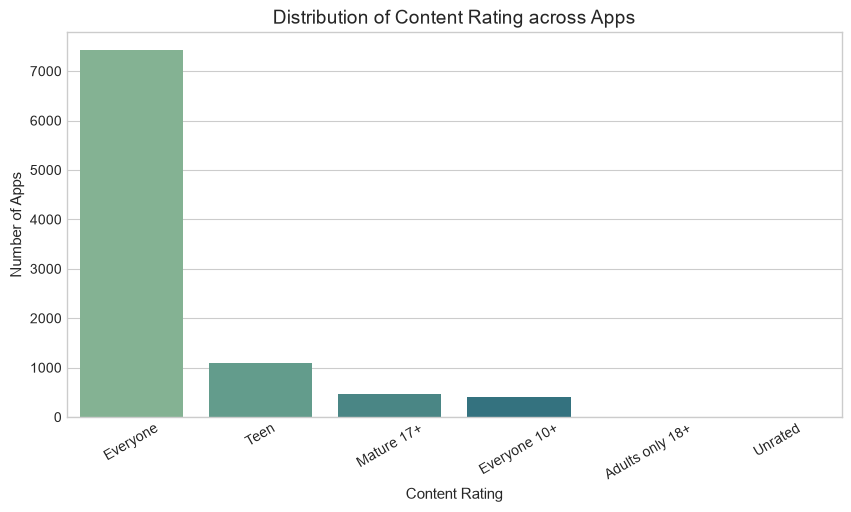

In [22]:
# Examine target age groups and audience segmentation across the platform
plt.figure(figsize=(10, 5))
order = df['Content Rating'].value_counts().index
sns.countplot(data=df, x='Content Rating', order=order, palette='crest')
plt.title('Distribution of Content Rating across Apps', fontsize=14)
plt.xlabel('Content Rating', fontsize=11)
plt.ylabel('Number of Apps', fontsize=11)
plt.xticks(rotation=30)
plt.show()

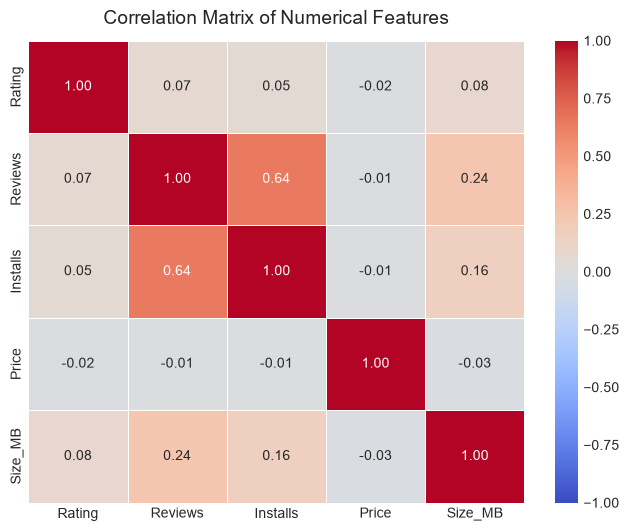

In [23]:
# Heatmap displaying Pearson correlation coefficients across numerical indicators
corr_cols = ['Rating', 'Reviews', 'Installs', 'Price', 'Size_MB']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features', fontsize=14, pad=12)
plt.show()

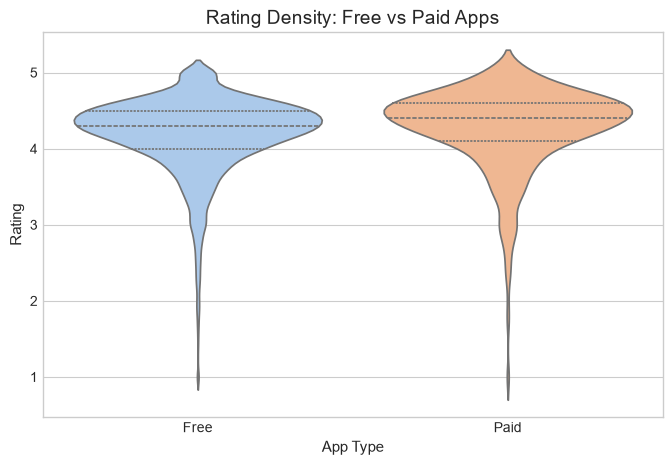

In [24]:
# Compare rating density and quartile distributions between Free and Paid software
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='Type', y='Rating', palette='pastel', inner='quartile')
plt.title('Rating Density: Free vs Paid Apps', fontsize=14)
plt.xlabel('App Type', fontsize=11)
plt.ylabel('Rating', fontsize=11)
plt.show()

In [25]:
# Save the preprocessed dataset with new engineered features to a CSV file
df.to_csv('googleplaystore_cleaned.csv', index=False)
print("Cleaned dataset successfully saved to 'googleplaystore_cleaned.csv'")

Cleaned dataset successfully saved to 'googleplaystore_cleaned.csv'
